# EPD-GIT-5534 — TP 6 (corrigé officiel) — Séance 6 : Industrialisation et clôture — Enseignante : Dr. Noulapeu Ngaffo Armielle

In [1]:
%matplotlib inline
import os
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
RNG = np.random.default_rng(5534)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})
print("numpy", np.__version__, "| pandas", pd.__version__)


numpy 2.4.6 | pandas 3.0.6


# TP 6 — Du modèle au service (corrigé officiel)

**EPD-GIT-5534 — TP 6 (corrigé officiel) — Séance 6 : Industrialisation et clôture — Enseignante : Dr. Noulapeu Ngaffo Armielle**

**Objectifs** : sauvegarder et recharger un pipeline **complet**
(standardisation + forêt) avec joblib ; mesurer la latence réelle de scoring et
raisonner la capacité ; surveiller l'AUC et la dérive des scores par tranche ;
rédiger la fiche MLOps ; s'auto-évaluer.

**Barème (20 pts)** : B1 pipeline complet sauvegardé — 5 pts · B2 latence et
capacité — 5 pts · B3 AUC et dérive — 4 pts · B4 fiche MLOps + quiz — 6 pts.


## Étape B1 — Sauvegarder le pipeline complet avec joblib (30 min)

Le test de vraie fin : sauvegarder **la standardisation en même temps que la
forêt**. Un pipeline partiel (modèle seul) produit des scores faux sur un
nouveau fichier — c'est le piège classique de l'industrialisation. Split
temporel strict : train < 2026-09-22.

In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import joblib

f = pd.read_csv("data/nosys_features.csv", parse_dates=["fenetre"])
variables = ["cpu_moy", "cpu_max", "ram_moy", "lat_moy", "lat_p99",
             "perte_moy", "temp_moy", "conso_moy", "capacite",
             "cpu_delta", "cpu_amplitude", "h_sin", "h_cos", "js_sin"]
f = f.dropna(subset=variables + ["incident_30min"])
cut = pd.Timestamp("2026-09-22")            # JAMAIS de shuffle
tr, te = f[f.fenetre < cut], f[f.fenetre >= cut]
print(f"train : {len(tr)} fenêtres, {int(tr.incident_30min.sum())} positives")
print(f"test  : {len(te)} fenêtres, {int(te.incident_30min.sum())} positives")

pipe = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                           class_weight="balanced", random_state=5534,
                           n_jobs=2))
pipe.fit(tr[variables], tr.incident_30min)
os.makedirs("out", exist_ok=True)
joblib.dump(pipe, "out/nosys_pipeline.joblib")
print("pipeline sauvegardé dans out/nosys_pipeline.joblib "
      f"({os.path.getsize('out/nosys_pipeline.joblib')/1024:.0f} Ko)")

train : 24184 fenêtres, 56 positives
test  : 10368 fenêtres, 64 positives


pipeline sauvegardé dans out/nosys_pipeline.joblib (1145 Ko)


In [3]:
# Rechargement depuis out/ (comme le fera le service) et test de fidélité :
# scorer le train doit redonner les probabilités d'avant sauvegarde.
pipe2 = joblib.load("out/nosys_pipeline.joblib")   # chargé de out/, pas de data/
avant = pipe.predict_proba(tr[variables])[:100, 1]
apres = pipe2.predict_proba(tr[variables])[:100, 1]
print("écart max avant/après sauvegarde :", float(np.abs(avant - apres).max()))
assert np.allclose(avant, apres), "le pipeline rechargé ne rend pas les mêmes scores"
print("OK : le pipeline rechargé depuis out/ produit les mêmes probabilités.")

écart max avant/après sauvegarde : 0.0
OK : le pipeline rechargé depuis out/ produit les mêmes probabilités.


## Étape B2 — Mesurer la latence réelle de scoring (30 min)

`perf_counter` sur **1 000 prédictions réelles**, une fenêtre à la fois, puis
par lots de 100. Les chiffres de votre machine sont vos propres mesures —
c'est ça le livrable.

In [4]:
import time

Xd = te[variables].sample(1000, random_state=5534)   # DataFrame : noms de colonnes conservés
# échauffement (caches, allocations) avant mesure
for i in range(20):
    pipe2.predict_proba(Xd.iloc[[i]])

lat = []
for i in range(len(Xd)):
    t0 = time.perf_counter()
    pipe2.predict_proba(Xd.iloc[[i]])
    lat.append((time.perf_counter() - t0) * 1000)
lat = np.array(lat)
print(f"latence individuelle : moyenne {lat.mean():.1f} ms | p99 "
      f"{np.percentile(lat, 99):.1f} ms")
print(f"débit individuel : {60_000 / lat.mean():.0f} fenêtres/min/cœur")

t0 = time.perf_counter()
for i in range(0, 1000, 100):
    pipe2.predict_proba(Xd.iloc[i:i + 100])
par_lot = (time.perf_counter() - t0) * 1000 / 10
print(f"scoring par lots de 100 : {par_lot:.1f} ms/lot = "
      f"{100 * 60_000 / par_lot:.0f} fenêtres/min/cœur")

latence individuelle : moyenne 39.8 ms | p99 75.0 ms
débit individuel : 1507 fenêtres/min/cœur


scoring par lots de 100 : 36.0 ms/lot = 166527 fenêtres/min/cœur


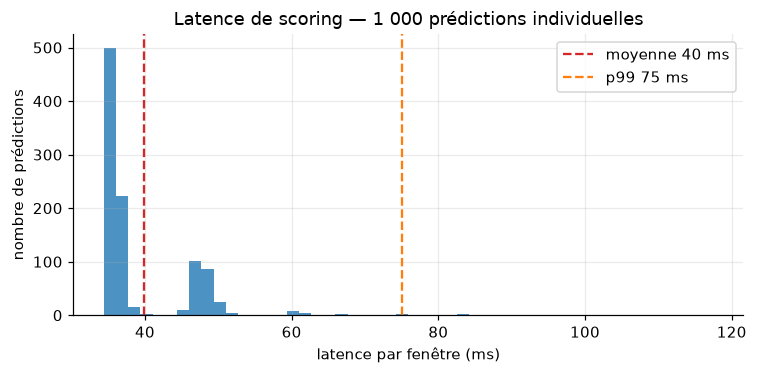

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(lat, bins=50, color="tab:blue", alpha=.8)
ax.axvline(lat.mean(), color="tab:red", ls="--",
           label=f"moyenne {lat.mean():.0f} ms")
ax.axvline(np.percentile(lat, 99), color="tab:orange", ls="--",
           label=f"p99 {np.percentile(lat, 99):.0f} ms")
ax.set_xlabel("latence par fenêtre (ms)")
ax.set_ylabel("nombre de prédictions")
ax.set_title("Latence de scoring — 1 000 prédictions individuelles")
ax.legend()
plt.tight_layout()
plt.show()

**Raisonnement de capacité.** NOSYS produit **1 152 fenêtres/jour** (8
serveurs, fenêtres de 10 min). Sur cette machine, un cœur à ~1 500
fenêtres/min en individuel traite la journée en moins d'une minute : marge
énorme, même à 10 cœurs occupés à autre chose. Le scoring **par lots** est
≈ 100× plus rapide par fenêtre ici (le dossier de référence du cours donnait
≈ 90×) parce
que le coût fixe d'appel (validation, copie, orchestration scikit-learn) est
amorti sur 100 fenêtres et que les arbres parallélisent en interne. Pourquoi
le p99 et pas seulement la moyenne ? Une moyenne cache les rares prédictions
très lentes — or c'est la queue qui fait dépasser le SLA.

## Étape B3 — AUC de test et dérive des scores (30 min)

AUC sur le test, puis suivi de la **proba moyenne par tranche de 2 jours** :
c'est la métrique qui reste lisible même quand la tranche ne contient aucun
incident.

In [6]:
from sklearn.metrics import roc_auc_score

proba_te = pipe2.predict_proba(te[variables])[:, 1]
auc = roc_auc_score(te.incident_30min, proba_te)
print(f"AUC test : {auc:.4f}")

# Dérive : proba moyenne par tranche de 2 jours du test
te3 = te.assign(proba=proba_te)
tranches = []
for debut in pd.date_range("2026-09-22", periods=5, freq="2D"):
    fin = debut + pd.Timedelta(days=2)
    sl = te3[(te3.fenetre >= debut) & (te3.fenetre < fin)]
    tranches.append({"tranche": f"{debut:%d/%m}", "n": len(sl),
                     "incidents": int(sl.incident_30min.sum()),
                     "proba_moyenne": sl.proba.mean(),
                     "taux_alertes": (sl.proba >= 0.5).mean()})
derive = pd.DataFrame(tranches)
print(derive.round(4).to_string(index=False))
# AUC par tranche : seulement là où la tranche contient les deux classes
aucs = {}
for i, debut in enumerate(pd.date_range("2026-09-22", periods=5, freq="2D")):
    fin = debut + pd.Timedelta(days=2)
    sl = te3[(te3.fenetre >= debut) & (te3.fenetre < fin)]
    if sl.incident_30min.nunique() == 2:
        aucs[f"{debut:%d/%m}"] = roc_auc_score(sl.incident_30min, sl.proba)
print("AUC mesurable par tranche :", {k: round(v, 4) for k, v in aucs.items()})

AUC test : 0.8000
tranche    n  incidents  proba_moyenne  taux_alertes
  22/09 2304         64         0.0061        0.0026
  24/09 2304          0         0.0001        0.0000
  26/09 2304          0         0.0001        0.0000
  28/09 2304          0         0.0001        0.0000
  30/09 1152          0         0.0107        0.0043
AUC mesurable par tranche : {'22/09': 0.7876}


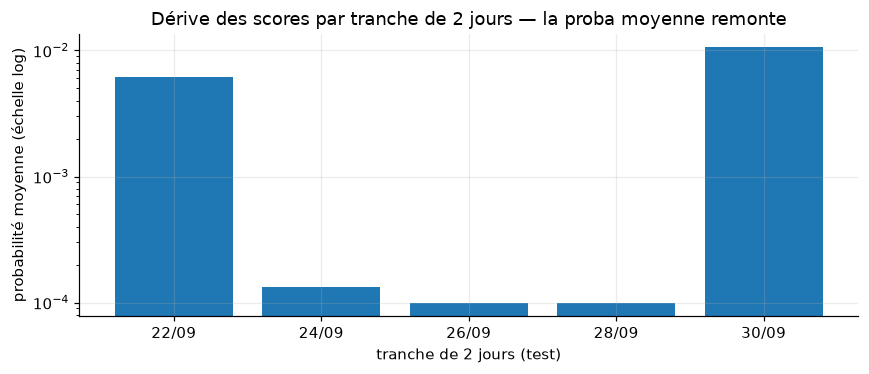

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(derive.tranche, derive.proba_moyenne, color="tab:blue")
ax.set_yscale("log")
ax.set_xlabel("tranche de 2 jours (test)")
ax.set_ylabel("probabilité moyenne (échelle log)")
ax.set_title("Dérive des scores par tranche de 2 jours — la proba moyenne remonte")
plt.tight_layout()
plt.show()

**Lecture.** AUC test ≈ 0,80 (AUC train = 1,0 : écart attendu, le modèle
mémorise le train — c'est pourquoi on ne juge que sur le test). Les tranches
sans incident (24/09 → 28/09) ont une proba moyenne ~0,0001–0,0002 : le calme
statistique. La dernière tranche remonte à ~0,011 — c'est **la distribution
des scores** qu'on surveille sur une tranche sans incident, pas l'AUC
(impossible sans les deux classes). Déclencheur de retraining : proba moyenne
> 0,005 pendant 48 h.

## Étape B4 — Fiche MLOps et quiz d'auto-évaluation

### Fiche MLOps — `nosys_pipeline` (une page)

**1. Plan de retraining.** Base : hebdomadaire (dimanche 02 h, données
glissantes de 30 jours, split temporel conservé). Déclencheurs chiffrés
anticipés : proba moyenne > 0,005 pendant 48 h ; taux d'alertes > 0,2 % des
fenêtres ; AUC < 0,70 dès que la tranche redevient mesurable. Chaque incident
confirmé par un analyste devient une étiquette neuve.

**2. Métriques surveillées.** AUC (≈ 0,80 au test, à re-mesurer chaque fois
que la tranche contient les deux classes) ; taux d'alertes (référence : 0,3 %
au début du test) ; proba moyenne par tranche de 2 jours (référence :
0,0001–0,0112) ; latence moyenne et p99 (mesures B2 de cette machine :
39,8 ms / 75,0 ms, ~1 507 fenêtres/min/cœur en individuel) ; distribution des entrées (moyennes
et quantiles des 14 features, alarme si PSI > 0,2).

**3. Procédure de rollback.** Garder les 5 dernières versions de
`out/nosys_pipeline.joblib` (nommage versionné `nosys_pipeline_vN.joblib`).
Qui : l'ingénieur d'astreinte. Quoi : restaurer la version précédente
(`cp nosys_pipeline_vN-1.joblib nosys_pipeline.joblib` + rechargement du
service). Délai : < 10 minutes. Déclencheur : le taux d'alertes double ou la
latence p99 dépasse 200 ms après une bascule.

### Quiz d'auto-évaluation (10 questions)

1. Le split strict sépare train et test à quelle date ? (séance 3/6)
2. Pourquoi 720 points en série horaire au TP 4 et quelle saisonnalité ?
3. Que vaut la MAE du SARIMA contre la persistance 24 h, en gain relatif ?
4. Pourquoi interdire le shuffle dans le split de fenêtres ?
5. Que mesure l'entropie de Shannon d'une session de logs ?
6. Que signifie précision@30 = 0,40 pour un analyste SOC ?
7. Pourquoi ne pas entraîner le détecteur supervisé sur la règle « > 5 échecs » ?
8. Que doit contenir le joblib sauvegardé pour que le service score juste ?
9. Que surveille-t-on sur une tranche de test sans incident ?
10. Pourquoi le p99 de latence compte-t-il plus que la moyenne pour le SLA ?

**Corrigé.**
1. **2026-09-22** — train < 22/09, test ≥ 22/09 (séances 3 et 6).
2. **30 jours de métriques 5 min agrégées en 1 h = 720 points ; saison
   journalière de 24 h** (TP 4, B1).
3. **≈ 3,0 pts contre 5,1 : gain ≈ 40 %** (TP 4, B2).
4. **Le temps ne se rééchantillonne pas : une ligne du futur dans le train
   fabrique une fuite et une MAE illusion** (séance 3).
5. **La diversité des comptes testés, en bits : 0 = un seul compte,
   log₂(k) = k comptes équilibrés ; le brute force a une entropie basse**
   (TP 5, B2).
6. **Parmi les 30 sessions les plus anormales, 12 sont de vraies attaques** :
   c'est le classement, outil de travail de l'analyste (TP 5, B3).
7. **C'est circulaire : le modèle apprendrait votre règle et ne ferait jamais
   mieux qu'elle** ; les étiquettes doivent venir d'incidents confirmés
   (TP 5, B4).
8. **Le pipeline complet : standardisation ET forêt** — un modèle seul produit
   des scores faux sur des données nouvelles (TP 6, B1).
9. **La distribution des scores (proba moyenne, taux d'alertes), pas l'AUC**,
   qui exige les deux classes (TP 6, B3).
10. **Une moyenne cache les rares prédictions très lentes ; la queue fait
    dépasser le SLA** (TP 6, B2).

**Livrable (à rendre)** : ① `out/nosys_pipeline.joblib` + test de fidélité
(B1), ② rapport de latence et raisonnement de capacité (B2), ③ AUC et suivi de
dérive (B3), ④ la fiche MLOps et le quiz corrigé ci-dessus (B4).